# Contenuti
- [Import](#Import)
- [Dataset casuale](#Dataset-casuale)
- [Esempio con scikit-learn](#Esempio-con-scikit-learn)
- [Implementazione K-means](#Implementazione-K-means)
    - [Selezione casuale dei centroidi iniziali](#Selezione-casuale-dei-centroidi-iniziali)
    - [Assegnazione dei pattern](#Assegnazione-dei-pattern)
    - [Aggiornamento dei centroidi](#Aggiornamento-dei-centroidi)
    - [K-means](#K-means)
    - [Esecuzione](#Esecuzione)
- [Speaker recognition: applicazione del clustering](#Speaker-recognition:-applicazione-del-clustering)
    - [Processing audio](#Processing-audio)
    - [Le feature utilizzate](#Le-feature-utilizzate)
    - [Dataset](#Dataset)
    - [EM e Speaker Recognition](#EM-e-Speaker-Recognition)
    - [Esercizio](#Esercizio)


# Esercitazione 6
Nell'esercitazione odierna si implementerà l'algoritmo *K-means*. Verrà chiesto di implementarne le parti fondamentali, verificarne il corretto funzionamento e infine di utilizzare l'algoritmo sviluppato per risolvere un problema di clustering.

# Import
Per prima cosa è necessario eseguire l'import delle librerie utilizzate durante l'esecitazione.

In [2]:
%matplotlib inline
########
# Nota: se appare un warning relativo a un memory leak su Windows,
# decommentare le seguenti 2 righe di codice:
#import os
#os.environ['OMP_NUM_THREADS'] = '2'
########

import numpy as np
import matplotlib.pyplot as plt
import random

import ml_utilities
import ml_visualization

# Dataset casuale
Durante la fase di implementazione del *K-means* verrà utilizzato un dataset di esempio generato casualmente per poter verificare in maniera semplice il corretto funzionamento dell'algoritmo.

Scikit-learn mette a disposizione la funzione [**make_blobs(...)**](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_blobs.html) per generare raggruppamenti di punti con distribuzione gaussiana. Variando i parametri *n_samples* (numero totale di punti generati), *centers* (numero di raggruppamenti) e *random_state* (seme iniziale per la generazione casuale) è possibile ottenere dataset differenti.

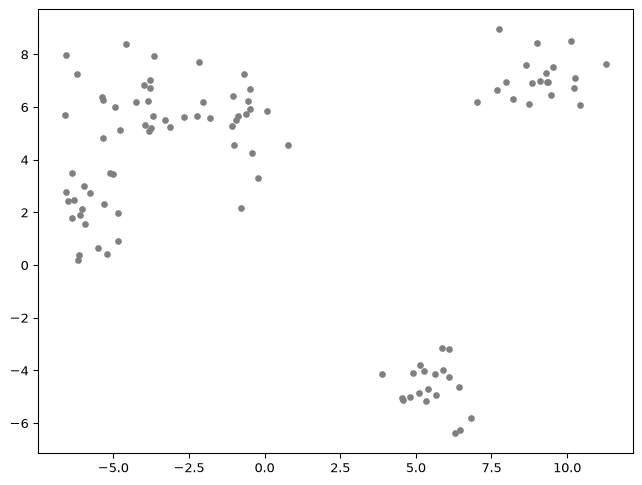

In [3]:
# Generazione di un dataset casuale
from sklearn.datasets import make_blobs

data, _ = make_blobs(n_samples=100, centers=5, random_state=1234)

plt.figure(num=0, dpi=96, figsize=(8, 6))
plt.scatter(data[:,0], data[:,1], c='grey', marker='o', s=16)
plt.show()

# Esempio con scikit-learn
La libreria Scikit-learn fornisce un'implementazione dei più importanti algoritmi di clustering. Per maggiori informazioni si rimanda alla [documentazione ufficiale](https://scikit-learn.org/stable/modules/clustering.html).

Di seguito un esempio di come utilizzare l'algoritmo *K-means* di Scikit-learn sul dataset appena generato.

C:\Users\anton\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\anton\Downloads\6 - KMeans\ml_visualization.py:119: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  plt.scatter(patterns[:, 0], patterns[:, 1],s=patternSize, c = patternColor,marker=marker, facecolor = '#000000')


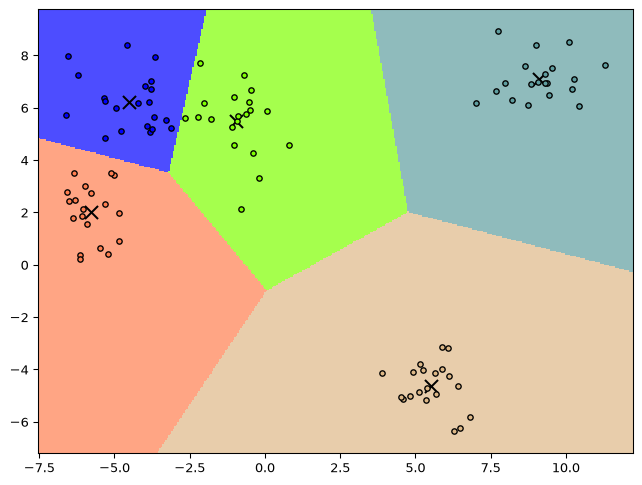

In [4]:
# Import della libreria
from sklearn.cluster import KMeans

# Definizione del numero di cluster attesi
n_clusters = 5

# Creazione dell'istanza di KMeans e addestramento
kmeans = KMeans(n_clusters=n_clusters, random_state=1234, n_init=1)
kmeans.fit(data)

# Visualizzazione dei risultati
plt.figure(num=0, dpi=96, figsize=(8, 6))
ml_visualization.draw_clustering_decision_boundaries(data, kmeans.labels_, kmeans.cluster_centers_, step=0.05)
plt.show()

È possibile ottenere i centroidi dei vari cluster utilizzando l'attributo **cluster\_centers\_** come mostrato nell'esempio seguente:

In [5]:
print('Centroidi ottenuti:\n', kmeans.cluster_centers_)

Centroidi ottenuti:
 [[-4.50296061  6.22703212]
 [ 5.51366983 -4.64045731]
 [ 9.11338955  7.10348958]
 [-0.95820208  5.50422472]
 [-5.7920073   1.9979973 ]]


Come per i classificatori, in Scikit-learn gli algoritmi di clustering mettono a disposizione il metodo **.predict(...)** che permette di ottenere l'indice del cluster a cui un pattern viene assegnato.

In [6]:
# Esempio di uso della funzione predict
print('Cluster predetti:\n', kmeans.predict([[-2.5, 0.0], [2.5, -4.0], [0.0, 5.0]]))

Cluster predetti:
 [4 1 3]


# Implementazione K-means
Per poter sviluppare la nostra versione dell'algoritmo si dovranno implementare le seguenti funzioni:
- **assign_patterns_to_clusters(...)** che restituisca un vettore contenente l’indice del cluster a cui è stato assegnato ogni pattern del dataset.
- **compute_centroids(...)** che dovrà restituire i nuovi centroidi calcolati come media dei pattern appartenenti ad ogni cluster.

Queste funzioni verranno successivamente richiamate all'interno della funzione **kmeans_execution(...)** che implementa l'intero *K-means*.

## Selezione casuale dei centroidi iniziali
Il primo passo del *K-means* richiede che vengano scelti casualmente $s$ (numero di cluster) pattern da utilizzare come centroidi iniziali.

La funzione **select_random_centroids(...)** restituisce $s$ centroidi scelti casualmente dai pattern di *data*. Sia il parametro *data* che il valore di ritorno sono **ndarray** bidimensionali in cui i pattern sono memorizzati per riga.

Nota: il parametro *seed* viene utilizzato per l’inizializzazione del generatore di numeri casuali. Per ulteriori dettagli si faccia riferimento alla documentazione della libreria [**random**](https://docs.python.org/3.6/library/random.html). A parità di *seed* il risultato della funzione non cambia in esecuzioni successive. La funzione **random.sample(...)** permette di selezionare un sottoinsieme di elementi da una lista (risolve il problema di selezionare più volte lo stesso elemento).

In [7]:
# La funzione restituisce s centroidi scelti casualmente tra i pattern di data

# data: ndarray bidimensionale in cui i pattern sono memorizzati per riga. Shape = (n_patterns, 2)
# s: numero intero, indica il numero di centroidi da selezionare
# seed: numero intero, utilizzato per inizializzare il generatore di numeri casuali

# Risultato: ndarray bidimensionale in cui i centroidi sono memorizzati per riga. Shape = (s, 2)

def select_random_centroids(data, s, seed):
    random.seed(seed)
    centroid_indices = random.sample(range(data.shape[0]), s)
    return data[centroid_indices]

## Assegnazione dei pattern
Ad ogni iterazione i pattern del dataset devono essere assegnati al cluster per cui è minima la distanza dal corrispondente centroide.

Si implementi la funzione **assign_patterns_to_clusters(...)** che restituisca un **ndarray** monodimensionale (*labels*) contenente l’indice del cluster a cui è stato assegnato ogni pattern. Per individuare il centroide più vicino ad ogni pattern è possibile utilizzare la funzione **compute_square_euclidean_distance(...)** già disponibile nella libreria ml_utilities.

Inoltre si dovrà calcolare e restituire la somma dei quadrati delle distanze di tutti i pattern $\boldsymbol{x}$ dai centroidi a cui sono stati assegnati (*sum_square_distances*), indicata con $J_e$:

$\Large{J_e = \sum_{i=1...s} \sum_{\boldsymbol{x} \in C_i} \lVert \boldsymbol{x} - \boldsymbol{\overline{x}_i} \rVert^2}$

$\Large{\boldsymbol{\overline{x}_i} = \frac{1}{n_i} \sum_{\boldsymbol{x} \in C_i} \boldsymbol{x}}$

dove $C_i$ è l'i-esimo cluster, $n_i$ il numero di pattern che contiene e $\boldsymbol{\overline{x}_i}$ il suo centroide (media).

In [8]:
# Esercizio 1: si completi il codice della funzione assign_patterns_to_clusters
# La funzione deve restituire un vettore contenente l'indice del cluster a cui
# è stato assegnato ogni pattern

# data: ndarray bidimensionale in cui i pattern sono memorizzati per riga. Shape = (n_patterns, 2)
# centroids: ndarray bidimensionale in cui i centroidi sono memorizzati per riga. Shape = (s, 2)

# Risultato 1: ndarray monodimensionale in cui sono memorizzate le etichette dei pattern. Shape = (n_patterns,)
# Risultato 2: valore numerico, somma dei quadrati delle distanze dei pattern dai centroidi a cui sono assegnati

def assign_patterns_to_clusters(data, centroids):
    data_count = data.shape[0]
    centroid_count = centroids.shape[0]
    distances = np.empty((data_count, centroid_count))
    
    for i in range(data_count):
        for j in range(centroid_count):
            distances[i, j] = ml_utilities.compute_square_euclidean_distance(data[i], centroids[j])

    sum_square_distances = sum(distances.min(axis=1))

    return distances.argmin(axis=1), sum_square_distances

## Aggiornamento dei centroidi
Una volta assegnati i pattern ai rispettivi cluster è necessario calcolare i nuovi centroidi come media dei pattern appartenenti ad ogni cluster.

Si implementi la funzione **compute_centroids(...)** in modo tale che questa restituisca un **ndarray** bidimensionale (*centroids*) contenente i nuovi centroidi (memorizzati per riga).

In [9]:
# Esercizio 2: si completi il codice della funzione compute_centroids
# La funzione deve restituire i nuovi centroidi calcolati come media
# dei pattern appartenenti ad ogni cluster

# data: ndarray bidimensionale in cui i pattern sono memorizzati per riga. Shape = (n_patterns, 2)
# labels: ndarray monodimensionale in cui sono memorizzate le etichette dei pattern. Shape = (n_patterns,)
# s: numero intero, indica il numero di centroidi da selezionare

# Risultato: ndarray bidimensionale in cui i centroidi sono memorizzati per riga. Shape = (s, 2)

def compute_centroids(data, labels, s):
    data_count = data.shape[0]
    centroids = np.zeros((s, data.shape[1]))
    count = np.zeros(s)
    
    for i in range(data_count):
        centroids[labels[i]] += data[i]
        count[labels[i]] += 1

    for i in range(s):
        if count[i] > 0:
            centroids[i] /= count[i]

    return centroids

## K-means
Le parti appena implementate costituiscono i blocchi fondamentali su cui si basa l'algoritmo *K-means*. La cella seguente definisce la funzione **kmeans_execution(...)** che, utilizzando le funzioni appena sviluppate, esegue l'algoritmo restituendo:

- l'indice del cluster a cui è stato assegnato ogni pattern di input (*labels*);
- la lista dei centroidi di ogni cluster (*centroids*);
- la somma dei quadrati delle distanze (*sum_square_distances*);
- il numero di iterazioni eseguite (*iteration_count*).

In [10]:
def kmeans_execution(data, s, max_iteration_count, seed):
    centroids = select_random_centroids(data, s, seed)
    iteration_count = 0
    modified = True
    while modified and iteration_count < max_iteration_count:
        labels, sum_square_distances = assign_patterns_to_clusters(data, centroids)
        new_centroids = compute_centroids(data, labels, s)
        modified = not np.array_equal(centroids, new_centroids)
        centroids = new_centroids
        iteration_count += 1

    return labels, centroids, sum_square_distances, iteration_count

## Esecuzione
Il codice contenuto nella cella seguente richiama la funzione **kmeans_execution(...)** sul dataset generato in precedenza e ne visualizza i risultati.

Si verifichi il funzionamento dell’algoritmo al variare del numero di cluster ($s$), del seme per la scelta casuale dei centroidi iniziali (*seed*) e del massimo numero di iterazioni consentite (*max_iteration_count*).

Somma quadrati distanze: 174.131
Numero di iterazioni: 4


C:\Users\anton\Downloads\6 - KMeans\ml_visualization.py:119: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  plt.scatter(patterns[:, 0], patterns[:, 1],s=patternSize, c = patternColor,marker=marker, facecolor = '#000000')


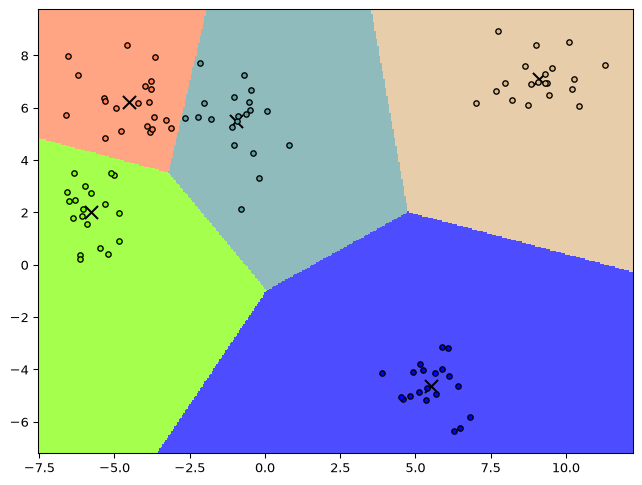

In [11]:
s = 5
seed = 1234
max_iteration_count = 50

labels, centroids, sum_square_distances, iteration_count = kmeans_execution(data, s, max_iteration_count, seed)

print('Somma quadrati distanze: %0.3f' % sum_square_distances)
print('Numero di iterazioni:', iteration_count)

plt.figure(num=0, dpi=96, figsize=(8, 6))
ml_visualization.draw_clustering_decision_boundaries(data, labels, centroids, step=0.05)
plt.show()

# Speaker recognition: applicazione del clustering

## Processing audio

Per processare in maniera efficace gli audio e le feature derivate, si utilizzerà la libreria [**librosa**](https://librosa.org/doc/latest/index.html) che fornisce un'ampia gamma di funzioni per l'analisi audio e musicale.
Nella prossima cella vediamo come installarla nel nostro ambiente da PyPI e come importarla nel nostro notebook.

In [12]:
%pip install librosa
import librosa
import IPython.display as ipd
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split

Note: you may need to restart the kernel to use updated packages.


A titolo di esempio e per mostrare in maniera grafica le feature MFCC, nella cella seguente carichiamo un audio di esempio tratto dalla prima sessione di registrazione.

Una volta caricato, con le funzioni `librosa.feature.melspectrogram(...)` e `librosa.feature.mfcc(...)` è possibile calcolare lo spettrogramma di Mel e le MFCC. Le due feature vengono poi visualizzate con la funzione `librosa.display.specshow(...)`.

In [13]:
y, sr = librosa.load('audio_digit.wav', sr=None)
ipd.Audio(y, rate=sr)

## Le feature utilizzate

Tra le feature più utilizzate per il riconoscimento del parlato troviamo le **MFCC (Mel Frequency Cepstral Coefficients)**. Si tratta di una rappresentazione particolarmente adatta per il riconoscimento vocale in quanto condensa le informazioni della traccia originale cercando di estrarre le informazioni utilizzate dal sistema uditivo umano. Hanno il grande pregio di essere feature molto compatte e per questo particolarmente indicate per poter essere processate dai comuni algoritmi di Machine Learning.

Per poter comprendere il contenuto delle MFCC è necessario prima di tutto comprendere come lo Spettrogramma di Mel viene calcolato ([qui una spiegazione semplificata](https://medium.com/analytics-vidhya/understanding-the-mel-spectrogram-fca2afa2ce53)).
Più in particolare, lo Spettrogramma di Mel si può visualizzare come un diagramma 2D dove nella dimensione orizzontale troviamo il tempo e in quella verticale le frequenze, con ampiezza (il colore) espressa in dB.

A partire dallo Spettrogramma di Mel è molto semplice ottenere le *MFCC* passando a una scala logaritmica e attraverso un'ulteriore trasformata coseno che decorrela i coefficienti dello spettrogramma ([spiegazione semplificata](https://medium.com/@tanveer9812/mfccs-made-easy-7ef383006040)).

Normalmente per ogni finestra temporale (*frame*) si mantengono 20 coefficienti primari. A questi si aggiungono altri 20 valori per la derivata prima e 20 per la derivata seconda, che indicano come una determinata frequenza varia nel tempo. In questo esercizio si utilizzeranno solo i 20 coefficienti primari, ma è possibile utilizzare anche le derivate calcolate con la funzione `librosa.feature.delta(...)`.

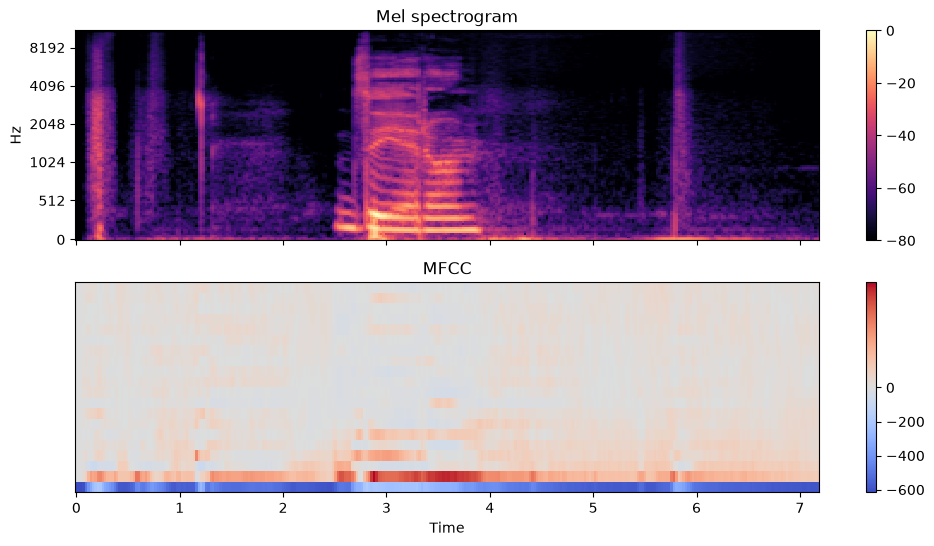

In [14]:
mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)

fig, ax = plt.subplots(nrows=2, ncols = 1, sharex=True, figsize=(12,6))

img = librosa.display.specshow(librosa.power_to_db(mel, ref=np.max), x_axis='time', y_axis='mel', ax=ax[0])
fig.colorbar(img, ax=[ax[0]])
ax[0].set(title='Mel spectrogram')
ax[0].label_outer()

img = librosa.display.specshow(mfccs, x_axis='time', ax=ax[1])
fig.colorbar(img, ax=[ax[1]])
ax[1].set(title='MFCC')
plt.show()

## Dataset

Il dataset è composto dalle tracce audio raccolte da 31 persone (grazie a tutti coloro che hanno contribuito!). Ciscuna persona ha registrato 10 tracce ripetendo i dieci digit in 4 sessioni diverse:
* 1 - Ambiente silenzioso (condizioni ottimali)
* 2 - Ambiente silenzioso (mattina poco dopo risveglio)
* 3 - Ambiente rumoroso (ad esempio all'esterno con traffico)
* 4 - Con rumore di fondo tipo TV o radio

Il **training set** contiene le tracce delle sessioni 1 e 4, per un totale di 620 pattern (2 x 31 x 10). Il **test set** contiene le tracce delle sessioni 2 e 3, per un totale di 620 pattern (2 x 31 x 10). Il dataset di train è fornito sotto forma di blob Pickle.

Al posto di distribuire i file audio grezzi, sono state pre-estratte feature "compatte" come descritto nelle celle seguenti.
Il **training set** è quindi fornito come un blob Pickle (un modo per serializzare oggetti Python) che contiene un dizionario con le seguenti chiavi:
* **features**: una lista contenente degli array NumPy di shape (173,) con delle feature rappresentanti delle tracce audio estratte con diversi algoritmi, che useremo per l'esercitazione successiva (su speech recognition).
* **mfccs**: una lista contenente degli array NumPy di shape (T, 20) con le feature MFCC estratte da ciascuna traccia audio, dove T è il numero di frame della traccia audio (variabile da traccia a traccia). Persona, sessione e digit di ciascun elemento di questa lista sono derivabili dalle tre liste seguenti ad essa allineate.
* **person_ids**: una lista contenente l'identificativo della persona che ha registrato ciascuna traccia audio.
* **session_ids**: una lista contenente l'identificativo della sessione in cui è stata registrata ciascuna traccia audio (1 o 4).
* **digits**: una lista contenente il digit pronunciato in ciascuna traccia audio (da 0 a 9).

In questa esercitazione ci concentreremo unicamente sul problema della speaker recognition partendo dalle MFCC estratte. Pertanto, **features** e **digits** non verranno utilizzate.

In [15]:
dataset_file_path = 'DBs/AudioDigits_ML26_27/audio_ml2627_train.pkl'
data = np.load(dataset_file_path, allow_pickle=True)

print('Elementi del dataset:', data.keys())
print('Shape delle feature compatte:', data['features'][0].shape)
print('Shape delle MFCC del primo audio:', data['mfccs'][0].shape)
print('Primi 10 ID delle persone:', data['person_ids'][:10])
print('Primi 10 ID delle sessioni:', data['session_ids'][:10])
print('Primi 10 digit pronunciati nelle tracce audio:', data['digits'][:10])
print('Lunghezze in frame (T) dei primi tre audio:', [mfcc.shape[0] for mfcc in data['mfccs'][:3]])

Elementi del dataset: dict_keys(['features', 'mfccs', 'person_ids', 'session_ids', 'digits'])
Shape delle feature compatte: (173,)
Shape delle MFCC del primo audio: (206, 20)
Primi 10 ID delle persone: [2, 25, 3, 0, 2, 1, 22, 14, 26, 1]
Primi 10 ID delle sessioni: [1, 1, 4, 4, 4, 4, 4, 4, 1, 1]
Primi 10 digit pronunciati nelle tracce audio: [9, 0, 2, 8, 3, 6, 1, 5, 3, 3]
Lunghezze in frame (T) dei primi tre audio: [206, 436, 371]


## EM e Speaker Recognition

Supponiamo di avere $n_a$ tracce audio per ognuno degli $n_k$ = 31 speaker. $n_a$ = 20 se consideriamo entrambe le sessioni. Per l'audio $j$-esimo dello speaker $i$-esimo carichiamo le MFCC ottenendo una rappresentazione $mfcc_{i,j}$ di shape ($t_{i,j}, 20$), dove $t_{i,j}$ è il numero di frame della traccia audio.

Ai fini del riconoscimento dello speaker **non è importante l'ordine dei $t_{i,j}$ frame in $mfcc_{i,j}$**: le **caratteristiche del tratto vocale** dipendono infatti dalla distribuzione statistica dei frame.
Pertanto, per ogni speaker $i$-esimo possiamo dunque concatenare tutti i frame ottenendo una singola rappresentazione $mfcc_i$ con $t_i = \sum_{j}{t_{i,j}}$ frame.

### Training dei modelli GMM

L'idea è quella di descrivere uno speaker $i$-esimo identificando dei cluster di frame simili nella rappresentazione $mfcc_i$ congiunta delle sue traccie audio. Anziché usare K-Means, che *non ci fornisce* un criterio diretto per l'assegnazione probabilistica, meglio usare un **Gaussian Mixture Model (GMM)** che ci permette di modellare la distribuzione dei frame di ciascuno speaker e di calcolare la probabilità che una nuova traccia audio appartenga a ciascuno speaker. Per ogni speaker $i$-esimo addestriamo dunque un GMM con $s$ componenti (iperparametro normalmente fisso per tutti gli speaker) utilizzando i frame in $mfcc_i$.
Il training, dopo aver definito `gmm_i = GaussianMixture(n_components=s, ...)` si esegue con la solita `gmm_i.fit(train_x)`.

### Predizione dello speaker

Dopo l'addestramento si hanno $n_k$ = 31 GMM, uno per speaker. Per assegnare uno speaker a una traccia audio (senza etichetta) si calcolano le MFCC $mfcc_{test,j}$ applicando lo stesso preprocessing usato in training, e per ogni GMM si calcola la **log-likelihood media** dei frame nella traccia. Poiché l'ordine dei frame non è rilevante, i frame nella traccia si considerano indipendenti e le loro log-likelihood si sommano per calcolare la log-likelihood media. Il passaggio dalla somma alla media consente di gestire tracce con numero diversi di frame.

Lo speaker predetto è quello il cui GMM ha la log-likelihood media più alta, $\hat{i} = \arg\max_i \log p(mfcc_{test,j} \mid gmm_i)$. Si usa la log-likelihood e non il likelihood perché il prodotto di centinaia di valori molto piccoli produrrebbe underflow.

In Scikit-learn `gmm.score(X)` restituisce già la log-likelihood **media** su tutti i frame della traccia X passata (`gmm.score_samples(X)` quella di ogni frame nella traccia). Attenzione a non usare `gmm.predict(X)`, che restituisce la componente del singolo GMM e non lo speaker.

In [16]:
# 1. Split del dataset in training e validation set (per traccia audio o per sessione, si valuti di applicare cross-validation)
# 2. Addestramento del Gaussian Mixture Model (GMM) per ogni speaker, utilizzando le MFCC come feature:
#    gmm = GaussianMixture(n_components=s, covariance_type='diag', random_state=1234)
#    gmm.fit(speaker_train_x)
# 3. Per ogni speaker di validation/test, calcolare la log-likelihood delle feature MFCC rispetto a
#    tutti i modelli GMM addestrati e assegnare l'etichetta del modello con la log-likelihood più alta:
#    speaker_gmm.score(unknown_speaker_mfccs)
# 4. Misurare l'accuracy sul validation set

## Esercizio

L'obiettivo è **massimizzare l'accuracy sul test set**, ovvero riconoscere correttamente lo speaker di ciascuna delle 620 tracce audio registrate nelle sessioni 2 e 3. Il test set è fornito nel file `audio_ml2627_test_no_labels.pkl`: ha la stessa struttura del training set, ma contiene solo le chiavi **features** e **mfccs** (non sono disponibili né gli speaker, né i digit).

Per scegliere preprocessing e iperparametri (numero di componenti $s$, tipo di covarianza, aggiunta derivate, normalizzazione, ecc.) si scelga l'approccio di validazione che più si ritiene appropriato. Una volta scelta la configurazione, si riaddestrino i GMM su tutte le tracce di training (sessioni 1 e 4) applicando lo stesso preprocessing anche al test set.

### Suggerimenti per lo split
Per quanto riguarda lo split dei dati, è importante fare attenzione a un aspetto: **il validation set deve simulare le condizioni in cui verrà usato il modello**, ovvero riconoscere lo speaker di audio mai visti e registrati in condizioni diverse da quelle del training. Il test set finale è infatti composto dalle sessioni 2 e 3, con ambienti e rumori di fondo diversi da quelli delle sessioni 1 e 4 usate per l'addestramento.

Lo split va quindi fatto **a livello di tracce e non di singoli frame**. I frame essendo estratti da finestre consecutive e sovrapposte nella stessa traccia sono quasi identici tra loro. Dopo aver scelto quali tracce finiscono nel training set, tutte quelle di uno stesso utente si possono concatenare. Una buona strategia (da valutare) è dividere **per sessione**, addestrando ad esempio sulla 1 e validando sulla 4, in modo da misurare la capacità di generalizzare a nuove condizioni di registrazione. Infine, una volta scelti gli iperparametri, si possono riaddestrare i GMM su tutte le tracce disponibili (sessioni 1 e 4).

### Istruzioni per la competizione

Sul sito della competizione dovrà essere caricato uno zip contenente sia il file di testo `Es6Predictions.txt` che una cartella `Codice` contenente il codice (notebook e script) da utilizzare per replicare il risultato.

Il file `.zip` da caricare sul sito della competizione dovrà avere necessariamente la seguente struttura:
```
<nomefile>.zip
├── Codice
│   └── <tutto il codice usato per training e test del modello>
└── Es6Predictions.txt
```

NB: all'interno dello zip il file `Es6Predictions.txt` non deve essere contenuto in una cartella.

**Regole per la competition:**
- Non si possono usare le feature contenute in **features** e **digits** del dataset, ma solo le MFCC.
- Si può usare **qualunque tecnica di clustering** presente in Scikit-learn, oltre ai Gaussian Mixture Models.
- **Non è possibile usare classificatori** di nessun tipo, né modelli presenti in Scikit-learn, né reti neurali o transformer.
- Si possono variare a piacimento gli iperparametri dei metodi di clustering. Volendo, si possono usare iperparametri diversi per i modelli dei diversi speaker (ha senso?).
- È possibile applicare preprocessing ai dati (es. riscalatura, standardization, eccetera). Assicuratevi di non addestrarli anche sul test set: il preprocessing si addestra sul training set (metodo `.fit_transform()` su Scikit-learn) e si applica al test set (metodo `.transform()` su Scikit-learn).
- È possibile **ridurre** il dataset rimuovendo dati anomali (*cleaning*).
- È possibile **derivare nuove feature** a partire da quelle esistenti (es. calcolo delle derivate con `librosa.feature.delta(...)`).
- **Non è possibile estendere il dataset** (*augmentation*) aggiungendo nuovi pattern o creandone di derivati dagli esistenti.
- La soglia per ricevere 2 punti in classifica è avere una **accuracy sul test set maggiore o uguale al 65%**.

In [17]:
# Caricamento del test set (senza etichette)
test_dataset_file_path = 'DBs/AudioDigits_ML26_27/audio_ml2627_test_no_labels.pkl'
test_data = np.load(test_dataset_file_path, allow_pickle=True)

print('Elementi del test set:', test_data.keys())
print('Numero di audio nel test set:', len(test_data['mfccs']))
print('Shape delle MFCC del primo audio:', test_data['mfccs'][0].shape)

Elementi del test set: dict_keys(['features', 'mfccs'])
Numero di audio nel test set: 620
Shape delle MFCC del primo audio: (281, 20)


In [35]:
import warnings
warnings.filterwarnings('ignore')

import time
import numpy as np
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from scipy.optimize import linear_sum_assignment
from scipy.special import logsumexp
from joblib import Parallel, delayed

train_mfccs = data['mfccs']
train_speakers = np.array(data['person_ids'], dtype=int)
train_sessions = np.array(data['session_ids'], dtype=int)

speaker_ids = np.unique(train_speakers)
K = len(speaker_ids)

USE_BALANCED = True

CONFIGS = [
    dict(cov='diag', s=16, reg=0.1, d=20),
    dict(cov='diag', s=16, reg=0.1, d=13),
    dict(cov='diag', s=8, reg=0.1, d=13),
    dict(cov='full', s=4, reg=0.01, d=20),
    dict(cov='full', s=8, reg=0.01, d=20),
    dict(cov='full', s=4, reg=0.01, d=13)
]

# Addestramento di un GMM
def fit_gmm(X, cfg):
    return GaussianMixture(
        n_components=cfg['s'],
        covariance_type=cfg['cov'],
        reg_covar=cfg['reg'],
        max_iter=100,
        random_state=1234
    ).fit(X)


# Calcolo dei log-posterior per ogni frame
def get_scores(train_x, train_y, test_x, cfg):
    d = cfg['d']
    train_x = [x[:, :d] for x in train_x]
    test_x = [x[:, :d] for x in test_x]

    scaler = StandardScaler().fit(np.vstack(train_x))

    X = [
        scaler.transform(np.vstack([
            x for x, y in zip(train_x, train_y) if y == spk
        ]))
        for spk in speaker_ids
    ]

    models = Parallel(n_jobs=-1)(
        delayed(fit_gmm)(x, cfg) for x in X
    )

    X_test = scaler.transform(np.vstack(test_x))
    scores = np.column_stack([
        model.score_samples(X_test) for model in models
    ])

    return scores - logsumexp(scores, axis=1, keepdims=True)


# Aggregazione dei punteggi per traccia
def track_scores(scores, lengths, mode):
    starts = np.r_[0, np.cumsum(lengths)[:-1]]

    if mode == 'll':
        return np.add.reduceat(scores, starts, axis=0) / lengths[:, None]

    return np.log(
        np.add.reduceat(np.exp(scores), starts, axis=0)
        / lengths[:, None] + 1e-12
    )


# Predizione con argmax o assegnazione bilanciata
def predict(scores, balanced):
    if balanced and len(scores) % K == 0:
        reps = len(scores) // K
        rows, cols = linear_sum_assignment(
            -np.repeat(scores, reps, axis=1)
        )
        pred = np.empty(len(scores), dtype=int)
        pred[rows] = cols // reps
        return speaker_ids[pred]

    return speaker_ids[scores.argmax(axis=1)]


# Validazione sulle sessioni 1 -> 4 e 4 -> 1
folds = []

for tr_sess, va_sess in [(1, 4), (4, 1)]:
    tr = np.where(train_sessions == tr_sess)[0]
    va = np.where(train_sessions == va_sess)[0]

    folds.append((
        [train_mfccs[i] for i in tr],
        train_speakers[tr],
        [train_mfccs[i] for i in va],
        train_speakers[va]
    ))


# Addestramento delle configurazioni
t0 = time.time()
val_scores = []

for i, cfg in enumerate(CONFIGS):
    val_scores.append([
        get_scores(tr_x, tr_y, va_x, cfg)
        for tr_x, tr_y, va_x, _ in folds
    ])

    print(f"Fit config {i+1}/{len(CONFIGS)}: {cfg} "
          f"[{time.time()-t0:.0f}s]")


# Valutazione di una configurazione o ensemble
def evaluate(ids, mode, balanced):
    accuracies = []

    for f, (_, _, val_x, val_y) in enumerate(folds):
        scores = np.mean([val_scores[i][f] for i in ids], axis=0)

        scores = track_scores(
            scores,
            np.array([len(x) for x in val_x]),
            mode
        )

        predictions = predict(scores, balanced)
        accuracies.append(np.mean(predictions == val_y))

    return np.mean(accuracies)


# Confronto delle configurazioni singole e degli ensemble
single = [
    evaluate([i], 'll', USE_BALANCED)
    for i in range(len(CONFIGS))
]

top3 = list(np.argsort(single)[-3:])

candidates = (
    [[i] for i in range(len(CONFIGS))]
    + [list(range(len(CONFIGS))), top3]
)

results = []

for ids in candidates:
    row = {
        (mode, balanced): evaluate(ids, mode, balanced)
        for mode in ('ll', 'post')
        for balanced in (False, True)
    }

    print(
        f"Config {ids} | "
        f"argmax ll: {row['ll', False]:.3f} "
        f"post: {row['post', False]:.3f} | "
        f"bilanciata ll: {row['ll', True]:.3f} "
        f"post: {row['post', True]:.3f}"
    )

    for mode in ('ll', 'post'):
        results.append((row[mode, USE_BALANCED], ids, mode))


# Migliore configurazione
best_acc, best_ids, best_mode = max(
    results, key=lambda x: x[0]
)

print("\nMigliore configurazione:", best_ids)
print("Scoring:", best_mode)
print("Balanced:", USE_BALANCED)
print(f"Accuracy di validazione: {best_acc:.3f}")


# Training finale e predizioni sul test
test_mfccs = test_data['mfccs']

scores = np.mean([
    get_scores(
        train_mfccs,
        train_speakers,
        test_mfccs,
        CONFIGS[i]
    )
    for i in best_ids
], axis=0)

scores = track_scores(
    scores,
    np.array([len(x) for x in test_mfccs]),
    best_mode
)

test_predictions = predict(scores, USE_BALANCED)

print("\nPredizioni generate:", len(test_predictions))
print("Speaker riconosciuti:", len(np.unique(test_predictions)))

Fit config 1/6: {'cov': 'diag', 's': 16, 'reg': 0.1, 'd': 20} [7s]
Fit config 2/6: {'cov': 'diag', 's': 16, 'reg': 0.1, 'd': 13} [14s]
Fit config 3/6: {'cov': 'diag', 's': 8, 'reg': 0.1, 'd': 13} [19s]
Fit config 4/6: {'cov': 'full', 's': 4, 'reg': 0.01, 'd': 20} [28s]
Fit config 5/6: {'cov': 'full', 's': 8, 'reg': 0.01, 'd': 20} [46s]
Fit config 6/6: {'cov': 'full', 's': 4, 'reg': 0.01, 'd': 13} [53s]
Config [0] | argmax ll: 0.539 post: 0.487 | bilanciata ll: 0.616 post: 0.645
Config [1] | argmax ll: 0.465 post: 0.437 | bilanciata ll: 0.547 post: 0.585
Config [2] | argmax ll: 0.419 post: 0.382 | bilanciata ll: 0.532 post: 0.527
Config [3] | argmax ll: 0.553 post: 0.548 | bilanciata ll: 0.677 post: 0.666
Config [4] | argmax ll: 0.532 post: 0.552 | bilanciata ll: 0.679 post: 0.653
Config [5] | argmax ll: 0.526 post: 0.518 | bilanciata ll: 0.619 post: 0.598
Config [0, 1, 2, 3, 4, 5] | argmax ll: 0.573 post: 0.615 | bilanciata ll: 0.666 post: 0.702
Config [np.int64(5), np.int64(3), np.int

La soluzione di base riaddestra un GMM per ogni speaker su tutte le tracce di training (sessioni 1 e 4), senza alcun preprocessing aggiuntivo delle MFCC, e assegna ogni traccia del test set allo speaker il cui GMM ha la log-likelihood più alta, utilizzando la funzione `predict_speaker(...)` definita in precedenza.

Si modifichino preprocessing e iperparametri per migliorare l'accuracy rispetto a questa soluzione di base.

In [ ]:
# Esercizio 3: si migliorino preprocessing e iperparametri per massimizzare
# l'accuracy sul test set. La soluzione di base riaddestra un GMM per ogni
# speaker su tutte le tracce di training (sessioni 1 e 4)

test_predictions = ...

Memorizzare le predizioni in un file di testo dal nome "Es6Predictions.txt" (un valore per riga). Il file deve contenere 620 righe, ognuna con l'identificativo dello speaker predetto per la corrispondente traccia del test set, **nello stesso ordine** in cui le tracce compaiono nel test set. La cella seguente genera, data la lista delle predizioni (*test_predictions*), il file di testo correttamente formattato.

In [36]:
# Creazione del file di testo
result_path = 'Es6Predictions.txt'
predictions = np.array(test_predictions, dtype=int)
np.savetxt(result_path, predictions, fmt='%i')
print('Ok')

Ok
